In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load Dataset
df = pd.read_csv("AirQuality (1).csv", sep=';')

print("First 5 rows:")
print(df.head())

print("\nShape of dataset:")
print(df.shape)

# Drop unwanted columns
df.drop(columns=['Unnamed: 15', 'Unnamed: 16', 'Date', 'Time'], inplace=True)

# Fix object columns having comma values
cols_to_fix = ['CO(GT)', 'C6H6(GT)', 'T', 'RH', 'AH']

for col in cols_to_fix:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Replace invalid values (-200) with NaN
df.replace(-200, np.nan, inplace=True)

print("\nMissing values before cleaning:")
print(df.isna().sum())

# Remove missing values
df.dropna(inplace=True)

# Remove duplicates
print("\nDuplicate rows before removing:", df.duplicated().sum())

df.drop_duplicates(inplace=True, ignore_index=True)

print("Duplicate rows after removing:", df.duplicated().sum())

print("\nDataset shape after cleaning:")
print(df.shape)




First 5 rows:
         Date      Time CO(GT)  PT08.S1(CO)  NMHC(GT) C6H6(GT)  PT08.S2(NMHC)  \
0  10/03/2004  18.00.00    2,6       1360.0     150.0     11,9         1046.0   
1  10/03/2004  19.00.00      2       1292.0     112.0      9,4          955.0   
2  10/03/2004  20.00.00    2,2       1402.0      88.0      9,0          939.0   
3  10/03/2004  21.00.00    2,2       1376.0      80.0      9,2          948.0   
4  10/03/2004  22.00.00    1,6       1272.0      51.0      6,5          836.0   

   NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)     T    RH  \
0    166.0        1056.0    113.0        1692.0       1268.0  13,6  48,9   
1    103.0        1174.0     92.0        1559.0        972.0  13,3  47,7   
2    131.0        1140.0    114.0        1555.0       1074.0  11,9  54,0   
3    172.0        1092.0    122.0        1584.0       1203.0  11,0  60,0   
4    131.0        1205.0    116.0        1490.0       1110.0  11,2  59,6   

       AH  Unnamed: 15  Unnamed: 16  
0  0

In [4]:
# Function to remove outliers
def remove_outliers(df, column, lower=0.01, upper=0.99):
    low = df[column].quantile(lower)
    high = df[column].quantile(upper)

    return df[(df[column] >= low) & (df[column] <= high)]

# Remove outliers from Temperature column
df = remove_outliers(df, 'T')

print("\nDataset shape after outlier removal:")
print(df.shape)



Dataset shape after outlier removal:
(811, 13)


In [5]:
# Final check for missing values
print("\nFinal missing values:")
print(df.isna().sum())




Final missing values:
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


In [6]:
# Define features and target
X = df.drop(columns=['T'])
y = df['T']

# Final NaN verification
print("\nNaN values in X:", X.isna().sum().sum())
print("NaN values in y:", y.isna().sum())

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)




NaN values in X: 0
NaN values in y: 0

Training Shape: (648, 12)
Testing Shape: (163, 12)


In [7]:
# ---------------- Decision Tree Regressor ---------------- #

dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("\nDECISION TREE RESULTS")
print("R2 Score:", r2_score(y_test, y_pred_dt))
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("MSE:", mean_squared_error(y_test, y_pred_dt))




DECISION TREE RESULTS
R2 Score: 0.9610086667746911
MAE: 0.6975460122699384
MSE: 0.9620245398773003


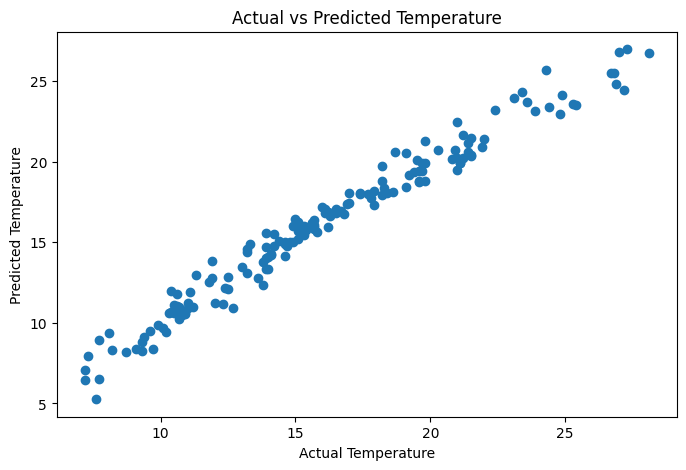

In [8]:

# ---------------- Visualization ---------------- #

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred_lr)

plt.xlabel("Actual Temperature")
plt.ylabel("Predicted Temperature")
plt.title("Actual vs Predicted Temperature")

plt.show()